In [1]:
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
len(words)

32033

In [3]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [4]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:3]:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
... ---> a
..a ---> v
.av ---> a
ava ---> .


In [5]:
X.shape, X.dtype, Y.shape, Y.dtype
# X: 16个样本，每个字符3个上下文

(torch.Size([16, 3]), torch.int64, torch.Size([16]), torch.int64)

In [6]:
X

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        [ 5, 13, 13],
        [13, 13,  1],
        [ 0,  0,  0],
        [ 0,  0, 15],
        [ 0, 15, 12],
        [15, 12,  9],
        [12,  9, 22],
        [ 9, 22,  9],
        [22,  9,  1],
        [ 0,  0,  0],
        [ 0,  0,  1],
        [ 0,  1, 22],
        [ 1, 22,  1]])

In [7]:
C = torch.randn((27,2))  # 2维，每个字母用2个参数表示

In [8]:
C

tensor([[ 0.5121,  1.1925],
        [ 1.2159,  0.1138],
        [ 0.5971,  1.8232],
        [ 0.6864,  1.9538],
        [-1.3463,  0.0893],
        [-1.3247,  0.7879],
        [ 0.4784, -0.4594],
        [ 0.8510, -0.9277],
        [ 2.3242, -0.2627],
        [-0.6663,  0.5792],
        [ 1.2929,  0.4011],
        [ 0.4317, -0.0565],
        [-2.0103,  1.4077],
        [-0.6968,  0.3000],
        [-1.4681, -0.6658],
        [ 0.3839, -3.2023],
        [ 0.6645,  0.1575],
        [-0.7581, -0.1187],
        [ 0.4539, -0.5751],
        [ 1.0656, -0.2846],
        [ 1.1241,  1.1475],
        [ 1.7272,  0.6338],
        [-0.0362, -0.4052],
        [-0.6213, -1.1004],
        [ 1.1842,  1.2521],
        [ 0.2183,  0.4043],
        [ 1.5219, -0.8626]])

In [9]:
idx = torch.tensor([0, 2]) 
C[idx]

tensor([[0.5121, 1.1925],
        [0.5971, 1.8232]])

In [10]:
C[X].shape # 对X每个元素查表，再堆叠

torch.Size([16, 3, 2])

In [11]:
C[X] # 等价于查表

tensor([[[ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925]],

        [[ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [-1.3247,  0.7879]],

        [[ 0.5121,  1.1925],
         [-1.3247,  0.7879],
         [-0.6968,  0.3000]],

        [[-1.3247,  0.7879],
         [-0.6968,  0.3000],
         [-0.6968,  0.3000]],

        [[-0.6968,  0.3000],
         [-0.6968,  0.3000],
         [ 1.2159,  0.1138]],

        [[ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925]],

        [[ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.3839, -3.2023]],

        [[ 0.5121,  1.1925],
         [ 0.3839, -3.2023],
         [-2.0103,  1.4077]],

        [[ 0.3839, -3.2023],
         [-2.0103,  1.4077],
         [-0.6663,  0.5792]],

        [[-2.0103,  1.4077],
         [-0.6663,  0.5792],
         [-0.0362, -0.4052]],

        [[-0.6663,  0.5792],
         [-0.0362, -0.4052],
         [-0.6663,  0.5792]],

        [[-0.0362, -0

In [12]:
emb = C[X]
emb.shape

torch.Size([16, 3, 2])

In [13]:
# emb[sample, char_position, embedding_dim]                                          
#        ↑         ↑                ↑                                                  
#       dim0      dim1             dim2    
# emb[:, t, :] -> 所有样本的第 t 个字符
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], dim=1)

tensor([[ 0.5121,  1.1925,  0.5121,  1.1925,  0.5121,  1.1925],
        [ 0.5121,  1.1925,  0.5121,  1.1925, -1.3247,  0.7879],
        [ 0.5121,  1.1925, -1.3247,  0.7879, -0.6968,  0.3000],
        [-1.3247,  0.7879, -0.6968,  0.3000, -0.6968,  0.3000],
        [-0.6968,  0.3000, -0.6968,  0.3000,  1.2159,  0.1138],
        [ 0.5121,  1.1925,  0.5121,  1.1925,  0.5121,  1.1925],
        [ 0.5121,  1.1925,  0.5121,  1.1925,  0.3839, -3.2023],
        [ 0.5121,  1.1925,  0.3839, -3.2023, -2.0103,  1.4077],
        [ 0.3839, -3.2023, -2.0103,  1.4077, -0.6663,  0.5792],
        [-2.0103,  1.4077, -0.6663,  0.5792, -0.0362, -0.4052],
        [-0.6663,  0.5792, -0.0362, -0.4052, -0.6663,  0.5792],
        [-0.0362, -0.4052, -0.6663,  0.5792,  1.2159,  0.1138],
        [ 0.5121,  1.1925,  0.5121,  1.1925,  0.5121,  1.1925],
        [ 0.5121,  1.1925,  0.5121,  1.1925,  1.2159,  0.1138],
        [ 0.5121,  1.1925,  1.2159,  0.1138, -0.0362, -0.4052],
        [ 1.2159,  0.1138, -0.0362, -0.4

In [14]:
torch.unbind(emb, 1)

(tensor([[ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [-1.3247,  0.7879],
         [-0.6968,  0.3000],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.3839, -3.2023],
         [-2.0103,  1.4077],
         [-0.6663,  0.5792],
         [-0.0362, -0.4052],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 1.2159,  0.1138]]),
 tensor([[ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [-1.3247,  0.7879],
         [-0.6968,  0.3000],
         [-0.6968,  0.3000],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 0.3839, -3.2023],
         [-2.0103,  1.4077],
         [-0.6663,  0.5792],
         [-0.0362, -0.4052],
         [-0.6663,  0.5792],
         [ 0.5121,  1.1925],
         [ 0.5121,  1.1925],
         [ 1.2159,  0.1138],
         [-0.0362, -0.4052]]),
 tensor([[ 0.5121,  1.1925],
         [-1.3247,  0.7879],
         [

In [15]:
a = torch.arange(12)
a.shape

torch.Size([12])

In [16]:
a.view(3, 2, 2)

tensor([[[ 0,  1],
         [ 2,  3]],

        [[ 4,  5],
         [ 6,  7]],

        [[ 8,  9],
         [10, 11]]])

In [17]:
a.storage()

C:\Users\Hi\AppData\Local\Temp\ipykernel_37700\214256462.py:1: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  a.storage()


 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 12]

In [18]:
# torch底层存储的是一维，我们可以高效地用view来调整tensor shape
emb.shape

torch.Size([16, 3, 2])

In [19]:
emb.view(16, 6).shape

torch.Size([16, 6])

In [20]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [21]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # -1: 让torch自己推断
# emb 输入每个都是6维
# @ W1 -> 输出 100 维
h

tensor([[-0.9967,  0.9991,  0.1923,  ...,  0.9925,  0.9999,  0.9231],
        [-0.9994,  0.9949, -0.9739,  ...,  0.9979,  1.0000,  0.3453],
        [-0.9970, -0.7645, -0.9918,  ...,  0.9179,  0.9999,  0.0810],
        ...,
        [-0.9666,  0.9995,  0.6916,  ...,  0.9747,  0.9891,  0.2753],
        [-0.9561,  0.9976, -0.2256,  ...,  0.9946,  0.9997, -0.6382],
        [-0.9835,  0.9950,  0.9702,  ...,  0.6413, -0.2409, -0.7630]])

In [22]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [23]:
logits = h @ W2 + b2

In [24]:
logits.shape

torch.Size([16, 27])

In [25]:
counts = logits.exp() # exp 的导数就是它本身，方便计算
probs = counts / counts.sum(1, keepdims=True)

In [26]:
probs.shape # 16个样本，每个输入对应27个预测分布

torch.Size([16, 27])

In [27]:
probs[0].sum()

tensor(1.0000)

In [28]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0])

In [29]:
torch.arange(16)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

In [30]:
probs[torch.arange(16), Y]
# 每个索引管一个维度
# (arange(16)[0], Y[0]) = (0, Y[0])   →  probs[0, Y[0]]
# (arange(16)[1], Y[1]) = (1, Y[1])   →  probs[1, Y[1]]
# ...
# (arange(16)[15], Y[15]) = (15, Y[15]) →  probs[15, Y[15]]
# 拿到正确答案Y的概率

tensor([1.5831e-02, 1.1343e-04, 4.8504e-11, 9.2254e-09, 5.8240e-06, 2.8938e-09,
        1.1697e-11, 1.0351e-10, 9.8788e-08, 9.8762e-14, 1.8112e-03, 5.6090e-07,
        9.7378e-01, 1.2660e-06, 1.3461e-07, 2.9868e-08])

In [31]:
probs[torch.arange(16), Y].log() # log相乘便利性，方便计算mean

tensor([-4.1458e+00, -9.0843e+00, -2.3749e+01, -1.8501e+01, -1.2054e+01,
        -1.9661e+01, -2.5172e+01, -2.2991e+01, -1.6130e+01, -2.9946e+01,
        -6.3138e+00, -1.4394e+01, -2.6569e-02, -1.3580e+01, -1.5821e+01,
        -1.7326e+01])

In [32]:
loss = -probs[torch.arange(16), Y].log().mean() # 平均惊讶度
loss

tensor(15.5560)

In [33]:
# make it clear
X.shape, Y.shape

(torch.Size([16, 3]), torch.Size([16]))

In [52]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator = g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [35]:
sum(p.nelement() for p in parameters)

3481

In [36]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
counts = logits.exp()
probs = counts / counts.sum(1, keepdims=True)
loss = -probs[torch.arange(16), Y].log().mean() 
loss

tensor(20.2417)

In [37]:
F.cross_entropy(logits, Y)

tensor(20.2417)

In [38]:
for p in parameters:
    p.requires_grad = True

In [39]:
for _ in range(20):
    emb = C[X]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y)
    print(loss.item())
    for p in parameters:
        p.grad = None
    loss.backward()
    for p in parameters:
        p.data += -0.1 * p.grad

20.24171257019043
14.233867645263672
10.578411102294922
7.81959867477417
6.053427696228027
4.864985466003418
3.8876330852508545
3.076685667037964
2.403904914855957
1.8741711378097534
1.4853014945983887
1.189316749572754
0.9622984528541565
0.7972683906555176
0.6850724816322327
0.6084163188934326
0.5534398555755615
0.5118284821510315
0.478971004486084
0.4521176218986511


In [40]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [41]:
X.shape, Y.shape

(torch.Size([228146, 3]), torch.Size([228146]))

In [42]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator = g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [43]:
for p in parameters:
    p.requires_grad = True

In [44]:
for _ in range(20):
    emb = C[X]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y)
    print(loss.item())
    for p in parameters:
        p.grad = None
    loss.backward()
    for p in parameters:
        p.data += -0.1 * p.grad

19.505229949951172
17.0844783782959
15.776530265808105
14.833341598510742
14.002609252929688
13.253264427185059
12.57992172241211
11.983104705810547
11.470497131347656
11.051857948303223
10.709589004516602
10.407634735107422
10.12781047821045
9.864367485046387
9.61450481414795
9.37644100189209
9.148945808410645
8.931112289428711
8.7222318649292
8.521750450134277


In [59]:
# RESET
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator = g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

In [64]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre # from 0.001 to 1.0 

In [65]:
lri, lossi, lrei = [], [], []

for i in range(1000):
    
    # minibatch - randomly select batch from X
    ix = torch.randint(0, X.shape[0], (32,))
    
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    # print(loss.item())
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    lri.append(lr)
    lossi.append(loss.item())
    lrei.append(lre[i])

print(loss.item())

6.642201900482178


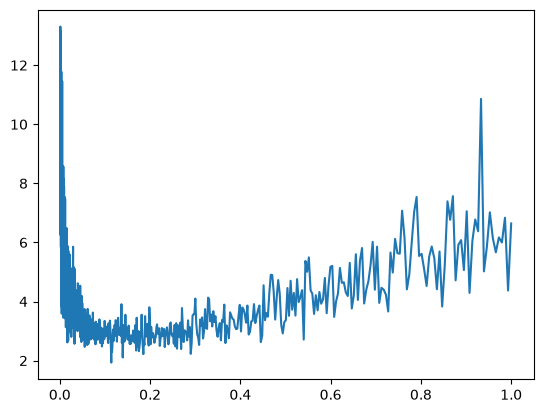

In [66]:
plt.plot(lri, lossi)

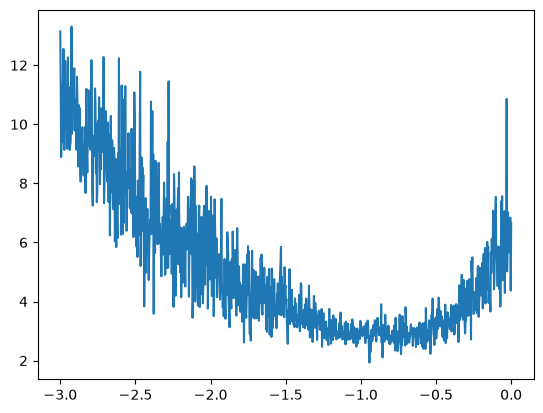

In [67]:
plt.plot(lrei, lossi)

In [70]:
# RESET
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator = g)
W1 = torch.randn((6, 100), generator = g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

In [80]:
# use lr = 0.1, and decay lr to 0.01 in later training
for i in range(1000):
    
    # minibatch - randomly select batch from X
    ix = torch.randint(0, X.shape[0], (32,))
    
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])
    # print(loss.item())
    for p in parameters:
        p.grad = None
    loss.backward()

    for p in parameters:
        p.data += -0.01 * p.grad

print(loss.item())

2.416914224624634


In [81]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Y)
loss

tensor(2.4896, grad_fn=<NllLossBackward0>)